# Two-Asset Portfolios: Why Correlation Matters

In this notebook, we will study how two assets can be combined into a portfolio and, especially, how **correlation changes portfolio risk**.

The central question is:

> **What happens to portfolio risk when correlation changes, while the individual assets remain the same?**

### Learning objectives

By the end of the notebook, you should be able to:

1. Calculate the expected return of a two-asset portfolio.
2. Calculate portfolio volatility.
3. Explain why correlation affects risk but not expected return.
4. Understand the diversification effect of lower correlation.
5. Identify the minimum-volatility portfolio.
6. Apply the same ideas to financial return data.

## 1. Start with the intuition

Suppose we combine two assets:

- **Asset 1** has a high expected return and high volatility.
- **Asset 2** has a lower expected return and lower volatility.

The portfolio return is simply a weighted average:

$$
E(R_P)=w_1E(R_1)+w_2E(R_2)
$$

with:

$$
w_1+w_2=1
$$

Portfolio risk is different. It depends not only on the risk of each asset, but also on **how the two assets move together**:

$$
\sigma_P=
\sqrt{
w_1^2\sigma_1^2+
w_2^2\sigma_2^2+
2w_1w_2\sigma_1\sigma_2\rho_{12}
}
$$

The new element is $\rho_{12}$, the correlation between the returns of the two assets.

### Key idea

> **Expected return depends on weights and expected returns. Portfolio risk also depends on correlation.**

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("ggplot")

## 2. Define our two assets

We will keep the characteristics of the two assets fixed throughout the first part of the notebook.

Only the correlation will change.

In [4]:
# Asset characteristics
ret1 = 0.20
ret2 = 0.10

std1 = 0.25
std2 = 0.15

# Initial portfolio weights
w1 = 0.40
w2 = 0.60

### Exercise 1 — Portfolio return

Before using Python, calculate the expected return of the portfolio by hand.

Use:

- $w_1=0.40$
- $w_2=0.60$
- $E(R_1)=20\%$
- $E(R_2)=10\%$

**Question:** What is the portfolio expected return?

In [ ]:
# EXERCISE 1
# Complete the calculation

portfolio_return = ...

print(f"Portfolio expected return: {portfolio_return:.2%}")

## 3. Create reusable portfolio functions

We will use the same two functions throughout the notebook.

In [5]:
def calc_portfolio_return(w1, w2, r1, r2):
    """Calculate the expected return of a two-asset portfolio."""
    return w1 * r1 + w2 * r2



In [6]:
def calc_portfolio_return(w1: float, w2: float, r1: float, r2: float) -> float:
    """Calculate the expected return of a two-asset portfolio.

    Args:
        w1 (float): Weight of asset 1 in the portfolio.
        w2 (float): Weight of asset 2 in the portfolio.
        r1 (float): Expected return of asset 1.
        r2 (float): Expected return of asset 2.

    Returns:
        float: Expected portfolio return.
    """

    return w1 * r1 + w2 * r2

### Same function with parameter validation

The following version performs the same calculation, but first checks that:

- all inputs are numeric;
- the portfolio weights add up to 1.

If any condition is not satisfied, the function raises an error instead of returning an incorrect result.

In [7]:
def calc_portfolio_return(w1: float, w2: float, r1: float, r2: float) -> float:
    """Calculate the expected return of a two-asset portfolio.

    Args:
        w1 (float): Weight of asset 1 in the portfolio.
        w2 (float): Weight of asset 2 in the portfolio.
        r1 (float): Expected return of asset 1.
        r2 (float): Expected return of asset 2.

    Returns:
        float: Expected portfolio return.
    """

    # Check that all arguments are numeric
    for name, value in {"w1": w1, "w2": w2, "r1": r1, "r2": r2}.items():
        if not isinstance(value, (int, float)):
            raise TypeError(f"{name} must be a numeric value")

    # Check that the portfolio weights add up to 1
    if not abs((w1 + w2) - 1) < 1e-8:
        raise ValueError("Portfolio weights must add up to 1")

    return w1 * r1 + w2 * r2

In [9]:

def calc_portfolio_std(w1, w2, std1, std2, rho):
    """Calculate the volatility of a two-asset portfolio."""
    return np.sqrt(
        w1**2 * std1**2
        + w2**2 * std2**2
        + 2 * w1 * w2 * std1 * std2 * rho)

# 4. Case 1: Perfect positive correlation

Let:

$$
\rho_{12}=1
$$

The two assets move perfectly together.

In this extreme case:

> **There is no diversification benefit.**

The portfolio volatility becomes:

$$
\sigma_P=w_1\sigma_1+w_2\sigma_2
$$

In [10]:
rho = 1

portfolio_return = calc_portfolio_return(w1, w2, ret1, ret2)
portfolio_std = calc_portfolio_std(w1, w2, std1, std2, rho)

print(f"Portfolio return: {portfolio_return:.2%}")
print(f"Portfolio volatility: {portfolio_std:.2%}")

Portfolio return: 14.00%
Portfolio volatility: 19.00%


### Exercise 2 — Predict before plotting

If $\rho=1$:

1. What do you expect the set of possible portfolios to look like in the return-volatility plane?
2. Can any portfolio have lower volatility than both individual assets?
3. Does changing the weights change expected return?

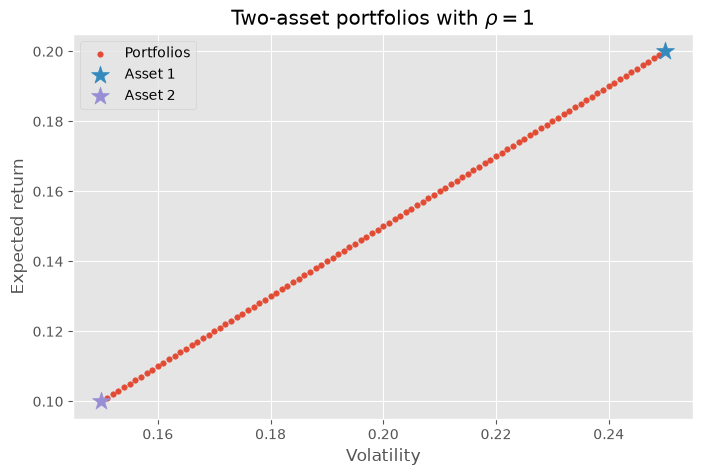

In [11]:
# Generate portfolios with different weights
weights_1 = np.linspace(0, 1, 101)

returns_rho1 = []
vols_rho1 = []

for w1_i in weights_1:
    w2_i = 1 - w1_i

    returns_rho1.append(
        calc_portfolio_return(w1_i, w2_i, ret1, ret2)
    )
    vols_rho1.append(
        calc_portfolio_std(w1_i, w2_i, std1, std2, rho)
    )

plt.figure(figsize=(8, 5))
plt.scatter(vols_rho1, returns_rho1, s=15, label="Portfolios")
plt.scatter(std1, ret1, marker="*", s=180, label="Asset 1")
plt.scatter(std2, ret2, marker="*", s=180, label="Asset 2")

plt.xlabel("Volatility")
plt.ylabel("Expected return")
plt.title(r"Two-asset portfolios with $\rho=1$")
plt.legend()
plt.show()

### Interpretation

With perfect positive correlation, all portfolios lie on a straight line between the two assets.

There is no additional risk reduction from combining the assets.

The only thing we are doing is moving from one asset to the other by changing the weights.

# 5. What if correlation is lower?

Now we keep **everything else unchanged** and modify only the correlation.

This is the central experiment of the notebook.

### Exercise 3 — Compare three correlations

Calculate the volatility of the same 40%-60% portfolio for:

- $\rho=1$
- $\rho=0$
- $\rho=-0.5$

Before running the code, predict:

> Which portfolio should have the lowest volatility?

In [1]:
# EXERCISE 3
correlations = [1, 0, -0.5]



### Main lesson

Notice something important:

- The assets are the same.
- Their expected returns are the same.
- Their individual volatilities are the same.
- The portfolio weights are the same.

Only **correlation** changed.

Yet portfolio volatility changed.

That is the diversification effect.

# 6. Case 2: Perfect negative correlation

Now let:

$$
\rho_{12}=-1
$$

The two assets move perfectly in opposite directions.

This is the strongest possible diversification case.

Portfolio volatility becomes:

$$
\sigma_P=
|w_1\sigma_1-w_2\sigma_2|
$$

For one particular combination of weights, portfolio volatility can even become zero.

### Exercise — Portfolios with Perfect Negative Correlation
Assume that the correlation between the two assets is:
$\rho_{12}=-1$
Generate 100 different portfolios by varying the weight of Asset 1 from 0 to 1. For each portfolio:
- calculate the weight of Asset 2;
- calculate the expected portfolio return;
- calculate the portfolio volatility.
Then plot the 100 portfolios in the return-volatility plane and include the two individual assets in the same figure.
Question: What do you observe about portfolio risk when the two assets are perfectly negatively correlated?

### Exercise 4 — Find the zero-volatility portfolio

For $\rho=-1$, the minimum-volatility weight of asset 1 is:

$$
w_1=\frac{\sigma_2}{\sigma_1+\sigma_2}
$$

1. Calculate $w_1$.
2. Calculate $w_2$.
3. Calculate the portfolio expected return.
4. Verify that portfolio volatility is zero.

In [ ]:
# EXERCISE 4

w1_min = ...
w2_min = ...

ret_min = ...
vol_min = ...

print(f"Weight asset 1: {w1_min:.2%}")
print(f"Weight asset 2: {w2_min:.2%}")
print(f"Portfolio return: {ret_min:.2%}")
print(f"Portfolio volatility: {vol_min:.2%}")

# 7. Compare several correlations

Now we can see the full picture.

We will calculate the portfolio opportunity set for several correlation values:

$$
\rho \in \{-1,-0.8,-0.5,0,0.5,1\}
$$

Before running the next cell, answer:

> **What do you expect to happen to portfolio risk as correlation decreases?**

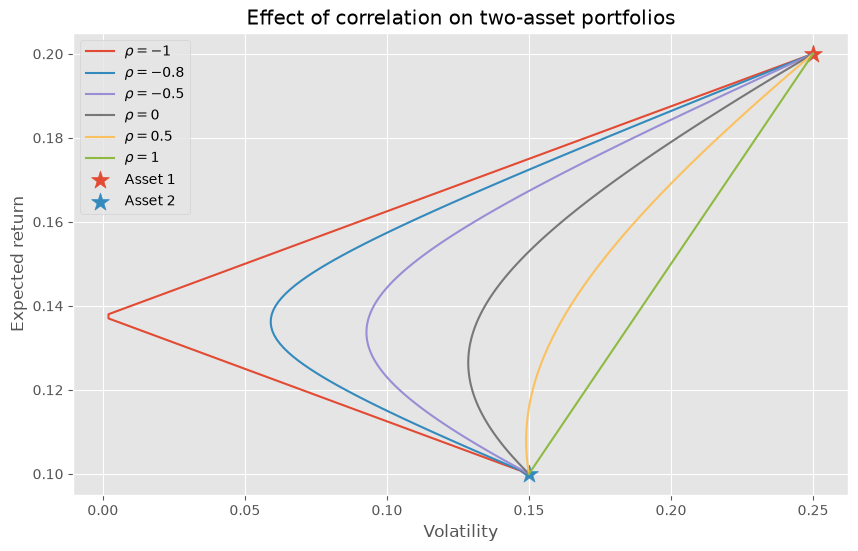

In [12]:
correlation_values = [-1, -0.8, -0.5, 0, 0.5, 1]

plt.figure(figsize=(10, 6))

for rho_i in correlation_values:
    portfolio_returns = []
    portfolio_vols = []

    for w1_i in weights_1:
        w2_i = 1 - w1_i

        portfolio_returns.append(
            calc_portfolio_return(w1_i, w2_i, ret1, ret2)
        )
        portfolio_vols.append(
            calc_portfolio_std(w1_i, w2_i, std1, std2, rho_i)
        )

    plt.plot(
        portfolio_vols,
        portfolio_returns,
        label=fr"$\rho={rho_i}$"
    )

plt.scatter(std1, ret1, marker="*", s=180, label="Asset 1")
plt.scatter(std2, ret2, marker="*", s=180, label="Asset 2")

plt.xlabel("Volatility")
plt.ylabel("Expected return")
plt.title("Effect of correlation on two-asset portfolios")
plt.legend()
plt.show()

### Exercise 5 — Interpret the figure

Answer in words:

1. Which correlation produces the greatest diversification benefit?
2. Which correlation produces no diversification benefit?
3. Does changing correlation change the expected return of a portfolio with fixed weights?
4. Why does the set of portfolios move to the left when correlation decreases?

**Key concept:** moving to the left means achieving the same expected return with less volatility.

# 8. The minimum-volatility portfolio

For any correlation between the two assets, the weight of asset 1 in the minimum-variance portfolio is:

$$
w_1^*=
\frac{
\sigma_2^2-\rho_{12}\sigma_1\sigma_2
}{
\sigma_1^2+\sigma_2^2-2\rho_{12}\sigma_1\sigma_2
}
$$

and:

$$
w_2^*=1-w_1^*
$$

This formula identifies the leftmost point of each portfolio curve.

In [ ]:
def min_variance_weights(std1, std2, rho):
    w1 = (std2**2 - rho * std1 * std2) / (
        std1**2 + std2**2 - 2 * rho * std1 * std2
    )
    w2 = 1 - w1
    return w1, w2

### Exercise 6 — Minimum volatility and correlation

Calculate the minimum-volatility portfolio for:

- $\rho=0.8$
- $\rho=0$
- $\rho=-0.5$

For each case, report:

- $w_1$
- $w_2$
- expected return
- volatility

Then answer:

> How does lower correlation affect the minimum achievable portfolio volatility?

In [ ]:
# EXERCISE 6

for rho_i in [0.8, 0, -0.5]:
    w1_i, w2_i = min_variance_weights(std1, std2, rho_i)

    ret_i = calc_portfolio_return(w1_i, w2_i, ret1, ret2)
    vol_i = calc_portfolio_std(w1_i, w2_i, std1, std2, rho_i)

    print(f"\nrho = {rho_i}")
    print(f"w1 = {w1_i:.2%}")
    print(f"w2 = {w2_i:.2%}")
    print(f"return = {ret_i:.2%}")
    print(f"volatility = {vol_i:.2%}")

# 9. From theory to data

So far, correlation was an input chosen by us.

Now we will estimate correlation from return data.

The original course material includes datasets designed to illustrate different dependence patterns. We will use one of them to connect the theoretical formulas with observed returns.

In [ ]:
# Positive-correlation example
url_pos = (
    "https://raw.githubusercontent.com/alfonso-santos/"
    "microcredencial-carteras-python/refs/heads/Feb-2025/"
    "Tema_1_Activos_Intro/data/precios_corr_pos.csv"
)

prices_pos = pd.read_csv(url_pos, index_col=0, parse_dates=True)
prices_pos.columns = ["Asset 1", "Asset 2"]

returns_pos = np.log(prices_pos).diff().dropna()

print("Estimated correlation:")
print(returns_pos.corr())

prices_pos.head()

In [ ]:
# Visualize the two price series
prices_pos.plot(figsize=(10, 4), title="Positively correlated assets")
plt.ylabel("Price")
plt.show()

### Exercise 7 — Estimate correlation from data

Using `returns_pos`:

1. Calculate the correlation between Asset 1 and Asset 2.
2. Calculate the mean return and volatility of each asset.
3. Create a 50%-50% portfolio.
4. Calculate its mean return and volatility.
5. Compare portfolio volatility with the volatility of the two individual assets.

In [ ]:
# EXERCISE 7

rho_data = ...

mean_returns = ...
volatilities = ...

weights = np.array([0.5, 0.5])

portfolio_returns = ...

print("Correlation:", rho_data)
print("\nMean returns:")
print(mean_returns)

print("\nVolatilities:")
print(volatilities)

print("\n50%-50% portfolio")
print("Mean return:", ...)
print("Volatility:", ...)

# 10. Final challenge — Build your own two-asset portfolio

Choose two stocks and download their daily Adjusted Close prices.

Suggested period:

**January 1, 2022 to January 1, 2026**

Then:

1. Calculate daily log returns.
2. Calculate the correlation between the two stocks.
3. Calculate the annualized return and volatility of each stock.
4. Generate 101 portfolios by varying the weight of stock 1 from 0% to 100%.
5. Plot all portfolios in the return-volatility plane.
6. Identify the minimum-volatility portfolio.
7. Explain whether diversification is important for this pair of stocks.

### Final question

> If you wanted stronger diversification, would you look for two assets with higher or lower correlation? Why?

In [ ]:
# FINAL CHALLENGE

import yfinance as yf

tickers = ["AAPL", "MSFT"]  # Replace with your chosen assets

data = yf.download(
    tickers,
    start="2022-01-01",
    end="2026-01-01",
    auto_adjust=False,
    progress=False
)["Adj Close"]

returns = np.log(data).diff().dropna()

returns.head()

# Summary

The main lesson of this notebook is:

> **Diversification does not come simply from owning more assets. It comes from combining assets that do not move perfectly together.**

Remember:

1. Portfolio expected return is a weighted average of asset expected returns.
2. Portfolio risk depends on asset volatilities **and correlation**.
3. Lower correlation generally creates greater diversification benefits.
4. With $\rho=1$, there is no diversification benefit.
5. With $\rho=-1$, diversification can theoretically eliminate volatility for a particular combination of weights.